In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay)


In [2]:
iris = load_iris(as_frame = True)
df = iris.frame
df["species"]= df["target"].map(dict(enumerate(iris.target_names)))
df.head(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa
5,5.4,3.9,1.7,0.4,0,setosa
6,4.6,3.4,1.4,0.3,0,setosa
7,5.0,3.4,1.5,0.2,0,setosa
8,4.4,2.9,1.4,0.2,0,setosa
9,4.9,3.1,1.5,0.1,0,setosa


In [3]:
print(df.shape)
print(df.columns.tolist())
print(df.dtypes)
print(df.isnull().sum())


(150, 6)
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target', 'species']
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
species               object
dtype: object
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64


In [4]:
print(df.duplicated().sum())
print(df["target"].value_counts())
print(df["target"].value_counts(normalize = True)*100)
df.describe()

1
target
0    50
1    50
2    50
Name: count, dtype: int64
target
0    33.333333
1    33.333333
2    33.333333
Name: proportion, dtype: float64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [5]:
features = list(iris.feature_names)
x = df[features]
y = df["target"]

print(x.head())
print(y.head())


   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


In [6]:
numeric_features = features

print(numeric_features)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [7]:
x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.20,random_state=42,stratify=y
)

print(x_train.shape)
print(x_test.shape)
print(y_train.value_counts(normalize = True))
print(y_test.value_counts(normalize = True))

(120, 4)
(30, 4)
target
0    0.333333
2    0.333333
1    0.333333
Name: proportion, dtype: float64
target
0    0.333333
2    0.333333
1    0.333333
Name: proportion, dtype: float64


In [8]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="median"))
    ]
)
preprocessor =ColumnTransformer(
    transformers=[
        ("numeric",numeric_pipeline,numeric_features)
    ]
)
print("Pipeline created successfully")

Pipeline created successfully


In [9]:
decision_tree = DecisionTreeClassifier(
    criterion = "gini",max_depth=4,min_samples_leaf =5, random_state=42
)
model=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("classifier",decision_tree)
    ]
)

model.fit(x_train,y_train)
print("Tree Model Successfully Trained")

Tree Model Successfully Trained


In [10]:
y_pred = model.predict(x_test)
y_probabilities = model.predict_proba(x_test)

confidence = y_probabilities.max(axis=1)

results = pd.DataFrame({
    "Actual":y_test.values,
    "Predicted":y_pred,
    "Actual_Species":[iris.target_names[i] for i in y_test.values],
    "Predicted_Species":[iris.target_names[i] for i in y_pred],
    "Confidence":confidence
})
print(results.head(10))

   Actual  Predicted Actual_Species Predicted_Species  Confidence
0       0          0         setosa            setosa         1.0
1       2          2      virginica         virginica         0.8
2       1          1     versicolor        versicolor         1.0
3       1          1     versicolor        versicolor         1.0
4       0          0         setosa            setosa         1.0
5       1          1     versicolor        versicolor         1.0
6       0          0         setosa            setosa         1.0
7       0          0         setosa            setosa         1.0
8       2          2      virginica         virginica         1.0
9       1          1     versicolor        versicolor         1.0


In [11]:
for i, name in enumerate(iris.target_names):
    actual_c = results[results["Actual"] == i]
    correct_c = actual_c[actual_c["Predicted"]==i]
    print(name,"| actual:",len(actual_c),"| predicted correctly:",len(correct_c),
         "| recall:",round(len(correct_c)/len(actual_c)*100,2),"%")

setosa | actual: 10 | predicted correctly: 10 | recall: 100.0 %
versicolor | actual: 10 | predicted correctly: 9 | recall: 90.0 %
virginica | actual: 10 | predicted correctly: 9 | recall: 90.0 %


In [12]:
incorrectPred = results[results["Actual"] != results["Predicted"]]
print(incorrectPred)
print("Total wrong Predictions:", len(incorrectPred))

    Actual  Predicted Actual_Species Predicted_Species  Confidence
23       2          1      virginica        versicolor         0.5
25       1          2     versicolor         virginica         1.0
Total wrong Predictions: 2


In [13]:
accuracy = accuracy_score(y_test,y_pred)
print(round(accuracy*100,2),"%")

93.33 %


In [14]:
print(classification_report(
        y_test,y_pred,target_names = list(iris.target_names),
        zero_division =0
    ))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



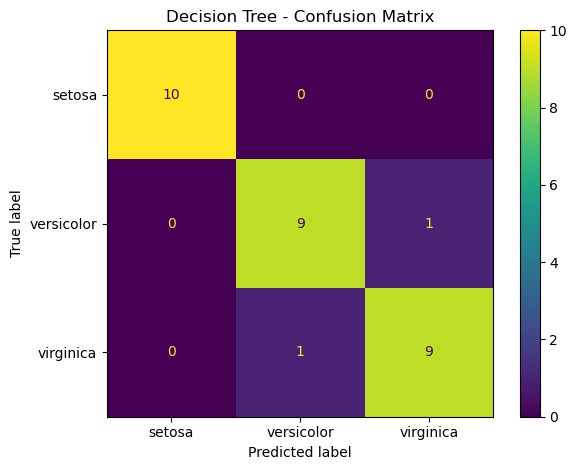

In [15]:
ConfusionMatrixDisplay.from_predictions(
    y_test,y_pred,display_labels = list(iris.target_names),
)
plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

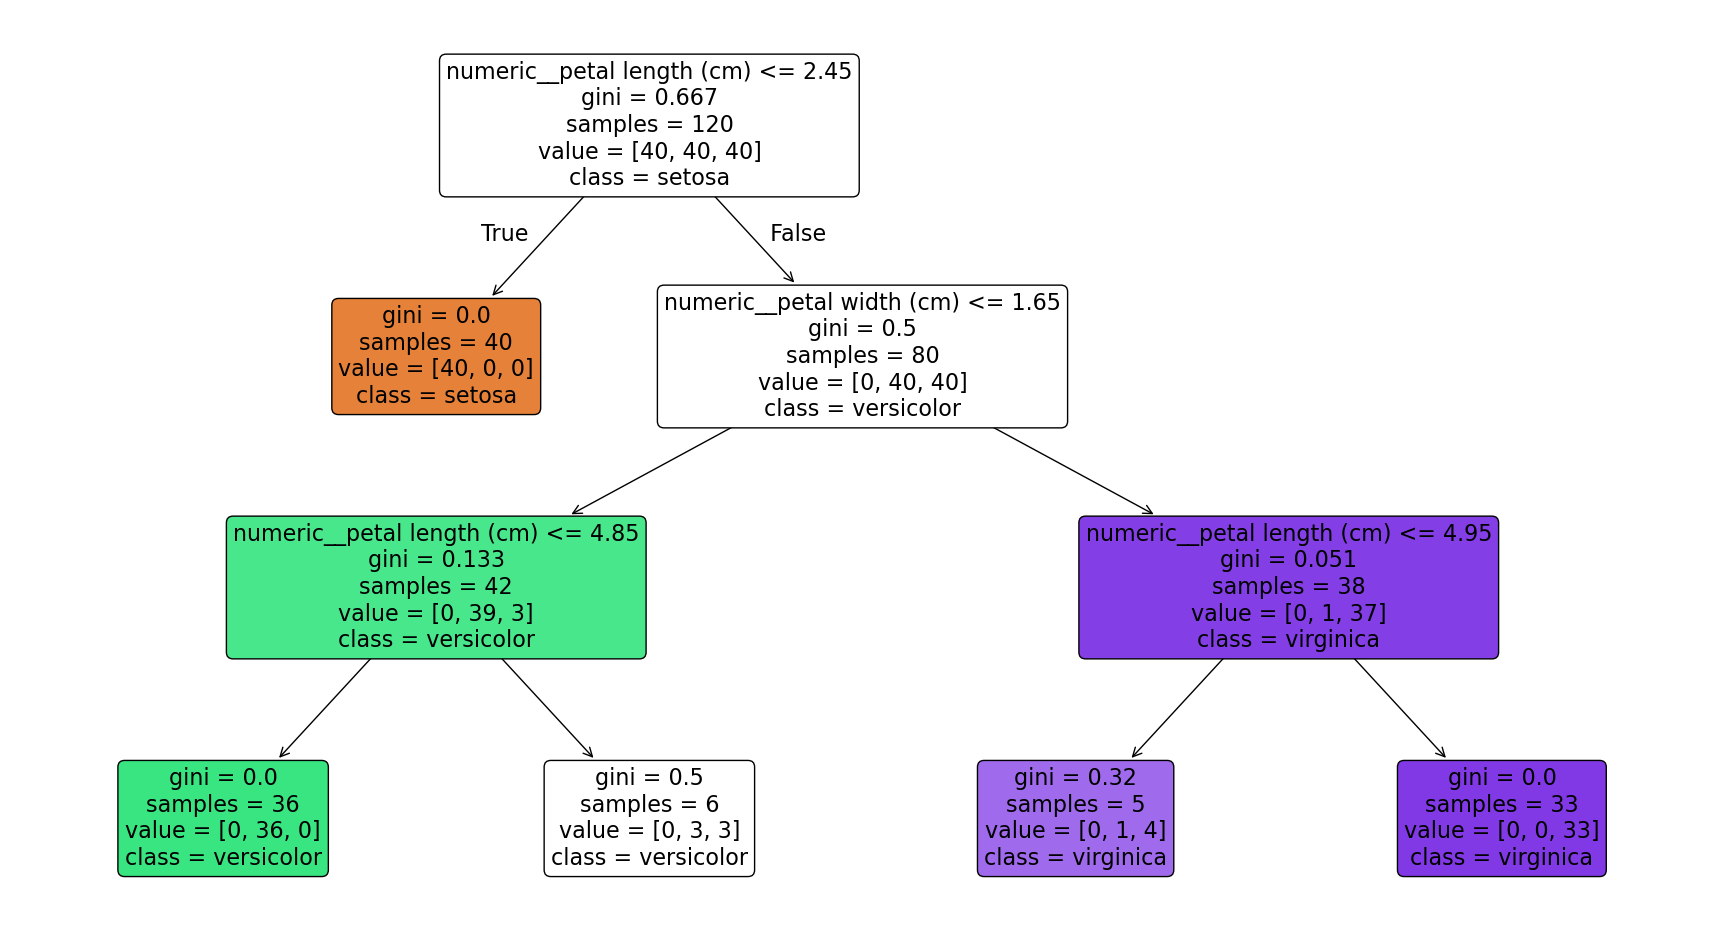

In [16]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
plt.figure(figsize=(22,12))
plot_tree(
    model.named_steps["classifier"],
    feature_names = feature_names,
    class_names = list(iris.target_names),
    filled = True, rounded = True, fontsize = 16
)
plt.show()

numeric__sepal length (cm)    0.0000
numeric__sepal width (cm)     0.0000
numeric__petal width (cm)     0.4308
numeric__petal length (cm)    0.5692
dtype: float64


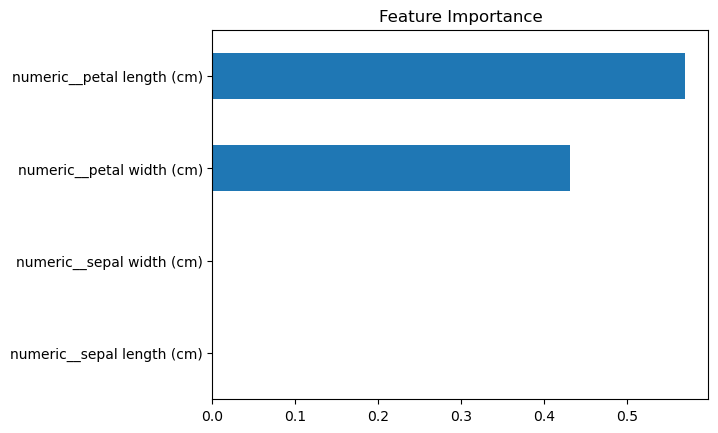

In [17]:
importance = pd.Series(
    model.named_steps["classifier"].feature_importances_, index=feature_names
).sort_values()
print(importance.round(4))
importance.plot.barh(title="Feature Importance")
plt.show()

In [18]:
new_flower = pd.DataFrame([[6.0,2.9,4.5,1.5]], columns=features)
pred = model.predict(new_flower)[0]
print("Predicted species:", iris.target_names[pred])
print("Probabilities :",model.predict_proba(new_flower).round(3))

Predicted species: versicolor
Probabilities : [[0. 1. 0.]]
